# Used laptop price estimator: data and model

This notebook walks through the data and the model behind the project's price estimator, one step at a time:

1. Load the laptop listings and inspect them
2. Find missing values and duplicates, and tidy the columns
3. Create the columns the model needs
4. Explore the data with questions and charts
5. Train a baseline (linear regression) and the project's model (LightGBM), and compare them
6. Turn one prediction into the lines printed on the price slip

It reuses the project's own code from `model/train.py` and `api/app`, so its numbers match the app. It runs top to bottom in Google Colab in a few minutes.

Project: https://github.com/iamelio/used-laptop-price-estimator

## Installing libraries

In [1]:
%pip install -q lightgbm "scikit-learn>=1.6"

## Getting the project code

Colab starts with an empty folder, so this clones the project from GitHub. Run from inside the project, it uses the files already there.

In [2]:
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/iamelio/used-laptop-price-estimator.git"
for candidate in (Path("."), Path("..")):
    if (candidate / "model" / "train.py").exists():
        ROOT = candidate.resolve()
        break
else:
    subprocess.run(["git", "clone", "-q", REPO], check=True)
    ROOT = Path("used-laptop-price-estimator").resolve()

sys.path[:0] = [str(ROOT / "model"), str(ROOT / "api")]

In [3]:
import contextlib
import io
import json

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

import train as tr

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("lightgbm:", lightgbm.__version__)

pandas: 3.1.1
scikit-learn: 1.9.1
lightgbm: 4.7.0


## Loading the data

2,160 laptop listings collected from a Spanish online shop in 2023 and published on Kaggle. Each row is one laptop for sale, new or refurbished, with its price in euros.

In [4]:
raw = pd.read_csv(tr.DATA_URL)

In [5]:
raw.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,Asus,ExpertBook,Intel Core i5,8,512,SSD,NaN,15.6,No,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,NaN,15.6,No,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,Asus,ExpertBook,Intel Core i3,8,256,SSD,NaN,15.6,No,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,MSI,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,No,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,NaN,15.6,No,669.01


In [6]:
raw.tail()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
2155,Razer Blade 17 FHD 360Hz Intel Core i7-11800H/...,Refurbished,Razer,Blade,Intel Core i7,16,1000,SSD,RTX 3060,17.3,No,2699.99
2156,Razer Blade 17 FHD 360Hz Intel Core i7-11800H/...,Refurbished,Razer,Blade,Intel Core i7,16,1000,SSD,RTX 3070,17.3,No,2899.99
2157,Razer Blade 17 FHD 360Hz Intel Core i7-11800H/...,Refurbished,Razer,Blade,Intel Core i7,32,1000,SSD,RTX 3080,17.3,No,3399.99
2158,Razer Book 13 Intel Evo Core i7-1165G7/16GB/1T...,Refurbished,Razer,Book,Intel Evo Core i7,16,1000,SSD,NaN,13.4,Yes,1899.99
2159,Razer Book FHD+ Intel Evo Core i7-1165G7/16GB/...,Refurbished,Razer,Book,Intel Evo Core i7,16,256,SSD,NaN,13.4,Yes,1699.99


In [7]:
raw.shape

(2160, 12)

In [8]:
raw.dtypes

Laptop              str
Status              str
Brand               str
Model               str
CPU                 str
RAM               int64
Storage           int64
Storage type        str
GPU                 str
Screen          float64
Touch               str
Final Price     float64
dtype: object

In [9]:
raw.describe()

,RAM,Storage,Screen,Final Price
count,2160.000000,2160.000000,2156.000000,2160.000000
mean,15.413889,596.294444,15.168112,1312.638509
std,9.867815,361.220506,1.203329,911.475417
min,4.000000,0.000000,10.100000,201.050000
25%,8.000000,256.000000,14.000000,661.082500
50%,16.000000,512.000000,15.600000,1031.945000
75%,16.000000,1000.000000,15.600000,1708.970000
max,128.000000,4000.000000,18.000000,7150.470000


In [10]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2160 non-null   str    
 1   Status        2160 non-null   str    
 2   Brand         2160 non-null   str    
 3   Model         2160 non-null   str    
 4   CPU           2160 non-null   str    
 5   RAM           2160 non-null   int64  
 6   Storage       2160 non-null   int64  
 7   Storage type  2118 non-null   str    
 8   GPU           789 non-null    str    
 9   Screen        2156 non-null   float64
 10  Touch         2160 non-null   str    
 11  Final Price   2160 non-null   float64
dtypes: float64(2), int64(2), str(8)
memory usage: 202.6 KB


In [11]:
raw.sample(n=3, random_state=42)

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
2079,MSI Modern 15 A11SBU-620XES Intel Core i7-1165...,Refurbished,MSI,Modern,Intel Core i7,32,1000,SSD,MX 450,15.6,No,1123.29
668,Thomson Neo White Intel Celeron N4020/4GB/64GB...,New,Thomson,Neo,Intel Celeron,4,64,eMMC,NaN,14.1,No,201.05
2073,MSI Modern 14 B11SB-420XES Intel Core i7-1165G...,Refurbished,MSI,Modern,Intel Core i7,32,1000,SSD,MX 450,14.0,No,997.74


## Missing values and duplicate records

In [12]:
raw.isna().sum()

Laptop             0
Status             0
Brand              0
Model              0
CPU                0
RAM                0
Storage            0
Storage type      42
GPU             1371
Screen             4
Touch              0
Final Price        0
dtype: int64

A blank `GPU` isn't really missing: it means the laptop has no dedicated graphics card. A few listings have no screen size.

In [13]:
specs = ["Brand", "Model", "CPU", "RAM", "Storage", "Storage type", "GPU", "Screen", "Status"]
print("Exact duplicate rows:", raw.duplicated().sum())
print("Rows that repeat another row's specs:", raw.duplicated(subset=specs).sum())

Exact duplicate rows: 0
Rows that repeat another row's specs: 787


Most repeated specs are colour variants of the same laptop. Later, the train/test split keeps every variant of a laptop on the same side, so the model is never tested on a laptop it has effectively already seen.

## Tidy text and numbers

In [14]:
raw["Brand"].value_counts().head(15)

Brand
Asus         415
HP           368
Lenovo       366
MSI          308
Acer         137
Apple        116
Dell          84
Microsoft     77
Gigabyte      48
Razer         37
Medion        32
LG            32
Alurin        29
PcCom         24
Samsung       22
Name: count, dtype: int64

The form offers 13 brands. Everything else becomes "Other".

In [15]:
raw["Storage"].value_counts().sort_index()

Storage
0         1
32       14
64       35
128      67
240       1
256     450
500      37
512     941
1000    570
2000     42
3000      1
4000      1
Name: count, dtype: int64

Storage uses shop rounding such as 500 and 1000 GB. The project maps these to the sizes people pick on the form, such as 512 GB and 1 TB.

In [16]:
raw["Status"].value_counts()

Status
New            1498
Refurbished     662
Name: count, dtype: int64

In [17]:
raw["Storage type"].value_counts()

Storage type
SSD     2062
eMMC      56
Name: count, dtype: int64

## Creating useful columns

The form asks for a laptop's year, type and price in naira, and none of them is a column in the data. `train.py` works them out:

- **Year:** from a year in the listing title, or else from the CPU generation. An Intel i7-1165G7 is 11th generation, so 2021.
- **Laptop type:** from the product line in the title. ROG is gaming, and ZenBook is an ultrabook.
- **Age:** 2023, when the data was collected, minus the year.
- **Price in naira:** the euro price × 1,700.

In [18]:
examples = raw.sample(n=6, random_state=7)
pd.DataFrame({
    "listing": examples["Laptop"].str.slice(0, 55),
    "CPU": examples["CPU"],
    "year": [tr.year_of(t, c) for t, c in zip(examples["Laptop"], examples["CPU"])],
    "type": [tr.laptop_type_of(t, g, c) for t, g, c in zip(examples["Laptop"], examples["GPU"], examples["CPU"])],
})

,listing,CPU,year,type
1288,Acer Extensa 15 EX215-22-R7D2 AMD Ryzen 3 3250...,AMD Ryzen 3,2019.0,Notebook
262,MSI Summit E13 Flip Evo A13MT-228ES Intel Evo ...,Intel Evo Core i7,2023.0,2-in-1
2137,Microsoft Surface Pro X Microsoft SQ1/8 GB/128...,Microsoft SQ1,NaN,2-in-1
1770,Apple Macbook Pro Intel Core i9/32GB/2TB SSD/R...,Intel Core i9,NaN,Workstation
60,ASUS VivoBook 15 F1500EA-EJ3022 Intel Core i7-...,Intel Core i7,2021.0,Notebook
788,Acer Predator Triton 500 SE PT516-51s-75K6 Int...,Intel Core i7,2021.0,Gaming


In [19]:
df = tr.load_dataset()
print(f"{len(raw)} listings, {len(df)} kept, {len(raw) - len(df)} dropped, almost all because no year could be worked out")
df[["brand", "laptop_type", "cpu", "series", "ram_gb", "storage_gb", "gpu", "age", "refurbished", "price_ngn"]].head()

2160 listings, 2061 kept, 99 dropped, almost all because no year could be worked out


,brand,laptop_type,cpu,series,ram_gb,storage_gb,gpu,age,refurbished,price_ngn
0,Asus,Notebook,Intel Core i5,ExpertBook,8.0,512.0,0.0,1.0,0.0,1715300.0
1,Other,Notebook,Intel Celeron / Pentium,Other,8.0,256.0,0.0,3.0,0.0,508300.0
2,Asus,Notebook,Intel Core i3,ExpertBook,8.0,256.0,0.0,1.0,0.0,1341300.0
3,MSI,Gaming,Intel Core i7,Katana,16.0,1024.0,1.0,1.0,0.0,2038300.0
4,HP,Notebook,Intel Core i5,15S,16.0,512.0,0.0,1.0,0.0,1137317.0


In [20]:
df["laptop_type"].value_counts()

laptop_type
Notebook       942
Gaming         584
Ultrabook      274
Workstation    133
2-in-1         128
Name: count, dtype: int64

In [21]:
df["age"].value_counts().sort_index()

age
0.0    246
1.0    548
2.0    809
3.0    314
4.0     54
5.0     60
6.0      9
7.0     21
Name: count, dtype: int64

## Filter records using questions

In [22]:
def naira(amount):
    return f"₦{amount:,.0f}"

gaming = df["laptop_type"] == "Gaming"
print("Gaming laptops at ₦3M or more:", len(df.loc[gaming & (df["price_ngn"] >= 3_000_000)]))
print("Apple or Dell laptops under ₦1.5M:", len(df.loc[df["brand"].isin(["Apple", "Dell"]) & (df["price_ngn"] < 1_500_000)]))
print("Laptops between ₦500k and ₦1M:", len(df.loc[df["price_ngn"].between(500_000, 1_000_000)]))
print("Median price:", naira(df["price_ngn"].median()))

Gaming laptops at ₦3M or more: 266
Apple or Dell laptops under ₦1.5M: 27
Laptops between ₦500k and ₦1M: 390
Median price: ₦1,783,300


## Exploring the data

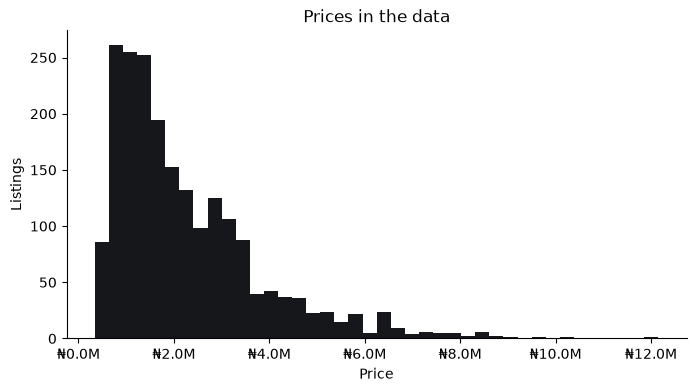

In [23]:
INK, ORANGE = "#15171B", "#FF5A1F"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
millions = plt.FuncFormatter(lambda value, _: f"₦{value / 1e6:.1f}M")

ax = df["price_ngn"].plot.hist(bins=40, color=INK)
ax.xaxis.set_major_formatter(millions)
ax.set(title="Prices in the data", xlabel="Price", ylabel="Listings")
plt.show()

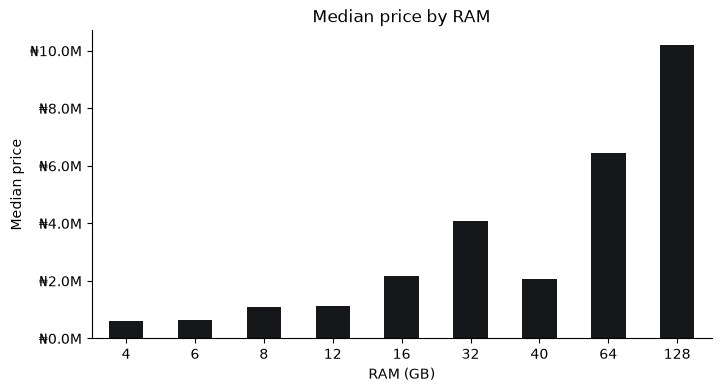

In [24]:
ax = df.groupby(df["ram_gb"].astype(int))["price_ngn"].median().plot.bar(color=INK, rot=0)
ax.yaxis.set_major_formatter(millions)
ax.set(title="Median price by RAM", xlabel="RAM (GB)", ylabel="Median price")
plt.show()

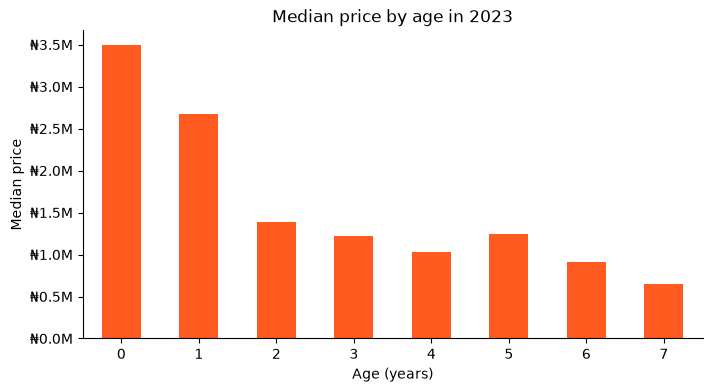

In [25]:
ax = df.groupby(df["age"].astype(int))["price_ngn"].median().plot.bar(color=ORANGE, rot=0)
ax.yaxis.set_major_formatter(millions)
ax.set(title="Median price by age in 2023", xlabel="Age (years)", ylabel="Median price")
plt.show()

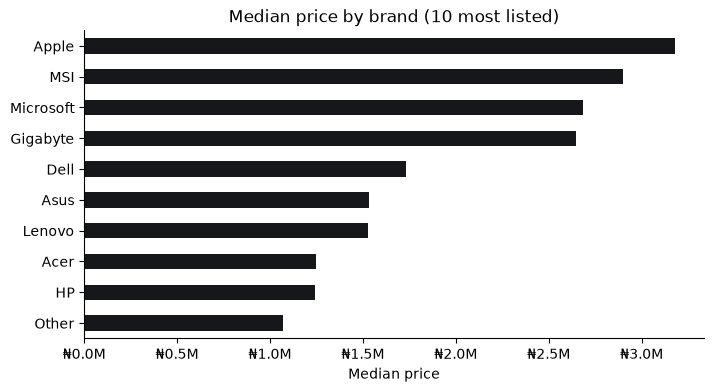

In [26]:
top_brands = df["brand"].value_counts().head(10).index
ax = df[df["brand"].isin(top_brands)].groupby("brand")["price_ngn"].median().sort_values().plot.barh(color=INK)
ax.xaxis.set_major_formatter(millions)
ax.set(title="Median price by brand (10 most listed)", xlabel="Median price", ylabel="")
plt.show()

## Splitting into training and test sets

15% of laptops are held back for testing. Colour variants of one laptop stay together, so the test set only has laptops the model has never seen.

In [27]:
dev, test = tr.holdout_split(df)
y = test["price_ngn"].to_numpy()
print(f"{len(dev)} laptops to train on, {len(test)} held back for testing")

1772 laptops to train on, 289 held back for testing


## Baseline: linear regression

A simple model to beat. It predicts the logarithm of the price, since prices are skewed and a feature like extra RAM tends to add a percentage, not a fixed amount. Text columns are one-hot encoded and blanks are filled in.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical = ["brand", "laptop_type", "cpu", "series"]
numeric = ["cpu_tier", "ram_gb", "storage_gb", "storage_type", "gpu", "screen_inches", "age", "refurbished"]

baseline = make_pipeline(
    ColumnTransformer([
        ("text", make_pipeline(SimpleImputer(strategy="constant", fill_value="Unknown"), OneHotEncoder(handle_unknown="ignore")), categorical),
        ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ]),
    LinearRegression(),
)
baseline.fit(dev[categorical + numeric], np.log(dev["price_ngn"]))
baseline_pred = np.exp(baseline.predict(test[categorical + numeric]))


def scores(actual, predicted):
    return {
        "Average error": naira(mean_absolute_error(actual, predicted)),
        "Median error": f"{np.median(np.abs(actual - predicted) / actual):.1%}",
        "R²": round(r2_score(actual, predicted), 3),
    }


pd.DataFrame({"Linear regression": scores(y, baseline_pred)})

,Linear regression
Average error,"₦497,395"
Median error,16.4%
R²,0.733


## The project's model: LightGBM

Gradient-boosted decision trees, using the settings `model/tune.py` found and saved in `model/best_lgb.json`. Three details matter for the app:

- **Monotonic constraints:** more RAM or storage never lowers the price, and more years never raise it.
- **"Not sure" answers:** training adds copies of some rows with graphics, screen size or model name blanked, so the model learns what a blank answer is worth.
- **Five seeds:** five models trained with different random seeds are averaged, which steadies the predictions.

Training takes under a minute.

In [29]:
params, rounds, seeds = tr.tuned()
boosters = tr.fit_seeds(dev, params, rounds, seeds)
model_pred = tr.predict(boosters, test)

pd.DataFrame({"Linear regression": scores(y, baseline_pred), "LightGBM": scores(y, model_pred)})

,Linear regression,LightGBM
Average error,"₦497,395","₦422,365"
Median error,16.4%,13.6%
R²,0.733,0.818


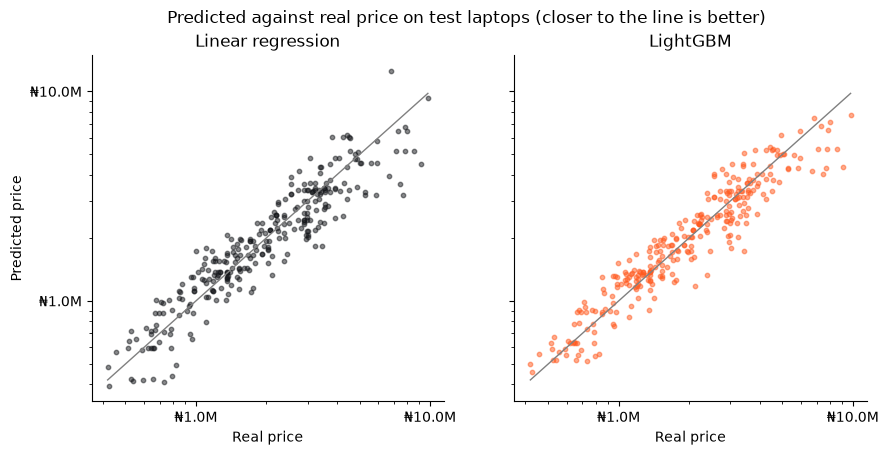

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, (name, predicted, colour) in zip(axes, [("Linear regression", baseline_pred, INK), ("LightGBM", model_pred, ORANGE)]):
    ax.scatter(y, predicted, s=10, alpha=0.5, color=colour)
    ax.plot([y.min(), y.max()], [y.min(), y.max()], color="grey", linewidth=1)
    ax.set(title=name, xscale="log", yscale="log", xlabel="Real price")
    ax.xaxis.set_major_formatter(millions)
    ax.yaxis.set_major_formatter(millions)
axes[0].set_ylabel("Predicted price")
fig.suptitle("Predicted against real price on test laptops (closer to the line is better)")
plt.show()

## The fair range

The slip shows a range as well as an estimate. `train.py` measures how far real prices land from predictions using cross-validation, and keeps the 10th to 90th percentile of the ratio. Training the final model on all the data also saves the files the API loads. This takes about a minute.

In [31]:
with contextlib.redirect_stdout(io.StringIO()):
    tr.main()

meta = json.loads((tr.ARTIFACTS / "meta.json").read_text())
low, high = meta["range_ratio"]
inside = (y >= model_pred * low) & (y <= model_pred * high)
print(f"Fair range: {low:.2f}× to {high:.2f}× the estimate")
print(f"Test laptops whose real price falls inside it: {inside.mean():.0%}")

Fair range: 0.78× to 1.32× the estimate
Test laptops whose real price falls inside it: 80%


## From prediction to price slip

The app explains each price with SHAP values: how much each answer pushed this laptop's price above or below the starting point, the average laptop. Condition, battery, and ages beyond the 7 years the data covers aren't in the data, so they're fixed adjustments applied afterwards.

This prices the example laptop from `contract/example-request.json` exactly as the app does.

In [32]:
from app.predictors.model import ModelPredictor
from app.schemas import LaptopSpecs

example = json.loads((ROOT / "contract" / "example-request.json").read_text())
slip = ModelPredictor().appraise(LaptopSpecs(**example))

print(f"{example['brand']} {example['model_name']}, {example['year']}")
print("Starting point:", naira(slip.base_value))
lines = pd.DataFrame([line.model_dump() for line in slip.contributions])[["label", "amount", "source"]]
display(lines.assign(amount=lines["amount"].map(lambda a: f"{a:+,}")))
print("Estimate:", naira(slip.estimate), f"(fair range {naira(slip.range.low)} to {naira(slip.range.high)})")

Dell XPS 13, 2021
Starting point: ₦1,631,000


,label,amount,source
0,Dell brand,"+320,000",model
1,Ultrabook build,"+128,000",model
2,Intel Core i7,"+249,000",model
3,XPS 13 model,"+149,000",model
4,16 GB RAM,"+64,000",model
5,512 GB storage,"-82,000",model
6,Graphics not known,"-6,000",model
7,Screen size not known,"-1,000",model
8,"Age, 5 years","-523,000",model
9,Good condition,"-96,000",adjustment


Estimate: ₦1,778,000 (fair range ₦1,385,000 to ₦2,340,000)


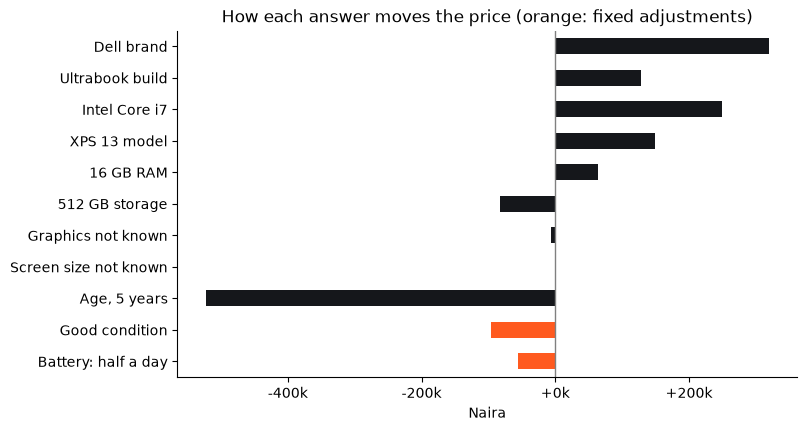

In [33]:
ordered = lines.iloc[::-1]
colours = [ORANGE if source == "adjustment" else INK for source in ordered["source"]]
ax = ordered.plot.barh(x="label", y="amount", color=colours, legend=False, figsize=(8, 4.5))
ax.axvline(0, color="grey", linewidth=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value / 1e3:+,.0f}k"))
ax.set(title="How each answer moves the price (orange: fixed adjustments)", xlabel="Naira", ylabel="")
plt.show()

## Known limits

- **European shop prices.** The data comes from a Spanish shop in 2023, converted at €1 = ₦1,700, so estimates run well above the Nigerian used market. The next step is a sample of Nigerian used listings, to calibrate or retrain.
- **Older laptops.** Few listings are more than 5 years old, and ages past 7 years are an estimate that continues the depreciation the model learned.
- **Newest chips.** The data ends in 2023, so Apple M3 and M4 aren't in it.